# Mixed Protocol Networks

## Introduction

**openfe** provides a number of protocols to estimate free energy differences, each with their own areas of applicability and limitations, suited to answering different types of scientific questions. While traditionally these protocols have been used in isolation, it is possible, thanks to the interchangeable nature of **openfe**, to combine them into a single network of transformations to leverage the strengths of each protocol.

This notebook demonstrates one way to create a mixed protocol network, combining two relative binding free energy approaches: the [Relative Hybrid Topology Protocol](https://docs.openfree.energy/en/latest/guide/protocols/relativehybridtopology.html#userguide-relative-hybrid-topology-protocol) and the [Separated Topologies Protocol](https://docs.openfree.energy/en/latest/guide/protocols/septop.html) to compute absolute binding affinities. A complete list of the available protocols along with their strengths and limitations can be found in the [protocol overview](https://docs.openfree.energy/en/latest/guide/protocols/index.html).

## Overview

In this tutorial, we will demonstrate how to create a mixed protocol network to compute absolute binding free energies for `three` distinct ligand scaffold series bound to $\beta$-secretase 1 (BACE1) taken from [Baumann et al.](https://doi.org/10.1021/acs.jctc.3c00282). The dataset contains a total of 18 ligands with 6 ligands in each of the three unique scaffold series grouped as `biaryl`, `spirocyclic` and `amide`, examples of each are shown below:

<img src="assets/series.png" width="300">

While each subset of ligands forms a congeneric series suitable for the hybrid topology approach, connections between the series are more challenging due to the large structural differences between the scaffolds. To overcome this, we will use the separated topologies approach to connect the three series together. Here we present one possible way to construct a mixed protocol with minimal manual intervention which can be broken down into the following steps:

- Plan a single LOMAP style hybrid topology binding free energy network with the Kartograf atom mapper and default lomap scorer
- Identify edges within this network between the three distinct series that are not suitable for the hybrid topology approach
- Build the transformations for the network, assigning the appropriate protocol to each transformation
- Execute and analyze the results to estimate the absolute binding free energies for each ligand

## Load and classify the ligands

First we start by loading the ligands from the provided SDF file and creating a mapping between the ligand name and respective series. The ligands are then converted to `SmallMoleculeComponents` for use within **openfe**.

<div altert class="alert alert-info"><b>Note:</b> Ligands should have partial charges assigned before planning the network, here we use pre-charged ligands but charges can be generated via the CLI or API.</div>
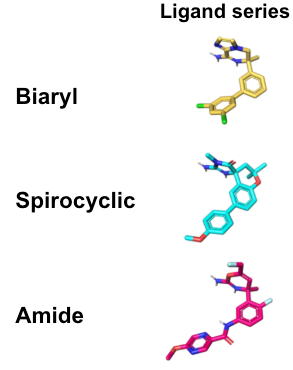

In [71]:
from rdkit import Chem
from gufe import SmallMoleculeComponent

ligands_file = "inputs/ligands.sdf"

supplier = Chem.SDMolSupplier(ligands_file, removeHs=False)
ligands = [SmallMoleculeComponent.from_rdkit(mol) for mol in supplier if mol is not None]

# Define a mapping between the ligand names and their respective series
ligand_series_mapping = {
    "lig_02": "biaryl",
    "lig_03": "biaryl",
    "lig_04": "biaryl",
    "lig_05": "biaryl",
    "lig_06": "biaryl",
    "lig_07": "biaryl",
    "lig_11": "spirocyclic",
    "lig_13": "spirocyclic",
    "lig_16": "spirocyclic",
    "lig_1a": "spirocyclic",
    "lig_32": "spirocyclic",
    "lig_36": "spirocyclic",
    "lig_41": "amide",
    "lig_45": "amide",
    "lig_67": "amide",
    "lig_69": "amide",
    "lig_74": "amide",
    "lig_81": "amide",
}

INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are present for SmallMoleculeComponent-bac489de520eadaa7126ee6641163303 (name: 'lig_41')
INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are present for SmallMoleculeComponent-3a85837a992c824bb4e0ef1eb4f03b21 (name: 'lig_03')
INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are present for SmallMoleculeComponent-0b73c8a6df07a0beed455c479519b97f (name: 'lig_07')
INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are present for SmallMoleculeComponent-d8bb71cb61021ff28fa31ae90db5e9af (name: 'lig_1a')
INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are present for SmallMoleculeComponent-e4c4a874b03c3a3cc36867807030f34f (name: 'lig_45')
INFO:gufekey.gufe.components.smallmoleculecomponent.SmallMoleculeComponent:Partial charges are prese

## Creating the `LigandNetwork`

Next we will create a single `LigandNetwork` containing all 18 ligands. This network will be used to identify edges between the three series that are not suitable for the hybrid topology approach, and will be assigned the separated topologies protocol later. In order to create a `LigandNetwork`, we need to define three components:

* **Atom Mapper**: Proposes potential atom mappings (descriptions of the alchemical change) for pairs of ligands. We will use the `KartografAtomMapper`.
* **Scorer**: Given an atom mapping, provides an estimate of the quality of that mapping (higher scores are better). We will use `default_lomap_scorer`.
* **Network Planner**: Creates the actual `LigandNetwork`; different network planners provide different strategies. We will create a `LOMAP` redundant network with the `generate_lomap_network` method.


In [29]:
import openfe

# Build the mapper using the default settings
mapper = openfe.KartografAtomMapper()
# Use the default LOMAP scorer to score the proposed atom mappings
scorer = openfe.lomap_scorers.default_lomap_score
# Use the LOMAP network planner to generate a redundant network
network_planner = openfe.ligand_network_planning.generate_lomap_network

# Build the network using the configured mapper, scorer, and network planner
network = network_planner(
    ligands=ligands,
    mappers=[mapper],
    scorer=scorer
)

INFO:kartograf.atom_mapper:#################################
INFO:kartograf.atom_mapper:Map Heavy Atoms 
INFO:kartograf.atom_mapper:#################################
INFO:kartograf.atom_mapper:Masking Atoms
INFO:kartograf.atom_mapper:Build Distance Matrix
INFO:kartograf.atom_mapper:Calculate Mapping
INFO:kartograf.atom_mapper:Find Maximal overlapping connected sets of mapped atoms
INFO:kartograf.atom_mapper:#################################
INFO:kartograf.atom_mapper:Map Hydrogen Atoms: 
INFO:kartograf.atom_mapper:#################################
INFO:kartograf.atom_mapper:Masking Atoms
INFO:kartograf.atom_mapper:Build Distance Matrix
INFO:kartograf.atom_mapper:Calculate Mapping
INFO:kartograf.atom_mapper:Find Maximal overlapping connected sets of mapped atoms
INFO:kartograf.atom_mapper:Filtering bond breaks
INFO:kartograf.atom_mapper:#################################
INFO:kartograf.atom_mapper:Map Heavy Atoms 
INFO:kartograf.atom_mapper:#################################
INFO:kartogra

## Visualize the `LigandNetwork`

Now we can visualize the `LigandNetwork` while highlighting the three distinct series using colours to match the examples shown above. The `biaryl` series is shown in yellow, the `spirocyclic` series in cyan, and the `amide` series in magenta. Edges between the series are shown in red while edges within the series are shown in black.

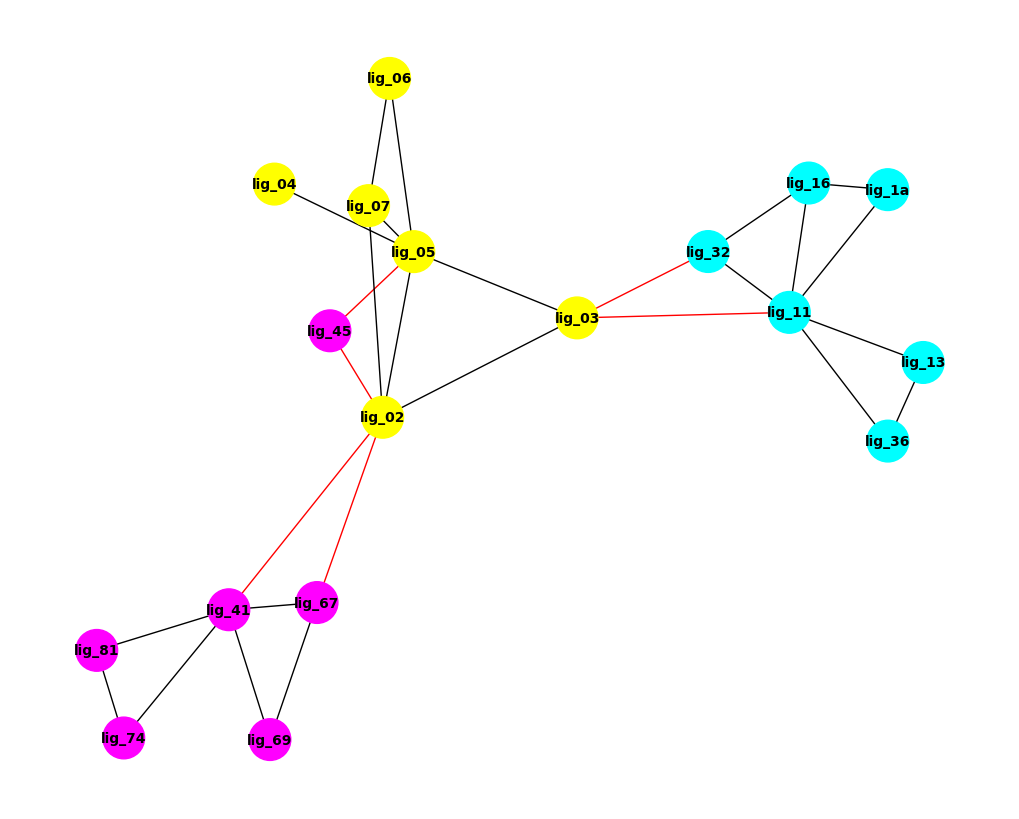

In [48]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

series_to_color = {
    "biaryl": "yellow",
    "spirocyclic": "cyan",
    "amide": "magenta"
}

network_graph = nx.Graph()
for edge in network.edges:
    network_graph.add_edge(edge.componentA.name, edge.componentB.name)
pos = nx.spring_layout(network_graph, seed=42)
node_colors = [series_to_color[ligand_series_mapping[node]] for node in network_graph.nodes()]
edge_colors = ["black" if ligand_series_mapping[edge[0]] == ligand_series_mapping[edge[1]] else "red" for edge in network_graph.edges()]
plt.figure(figsize=(10, 8))
nx.draw(network_graph, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=900, font_size=10, font_color='black', font_weight='bold')
plt.axis("off")
plt.show()

## Inspecting the atom mappings

Now we can inspect and compare the atom mappings and associated scores for edges between the series with those within each series. First lets inspect an edge between the `biaryl` and `spirocyclic` series involving ligands `lig_03` and `lig_11`. The atom mapping is shown below along with the associated score. The score is relatively low due to the large number of alchemical atoms required, indicating that this edge may be difficult to converge with the hybrid topology approach.

<div altert class="alert alert-info"><b>Reminder:</b> Shared core (mapped) atoms are shown in black and thoses unique to each end state are shown in red. Mapped atoms whoes element change during the simulation are shown in blue.</div>

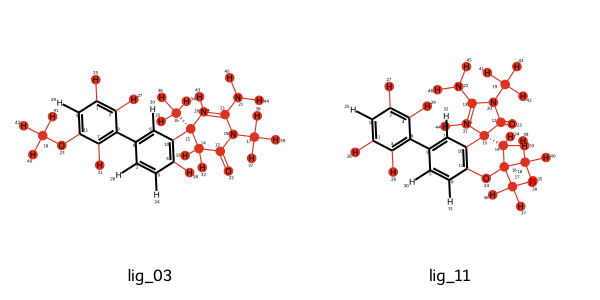

In [51]:
edge = [edge for edge in network.edges if {edge.componentA.name, edge.componentB.name} == {"lig_03", "lig_11"}][0]
edge

In [52]:
# Higher score is better
edge.annotations

{'score': 0.008208499862389881}

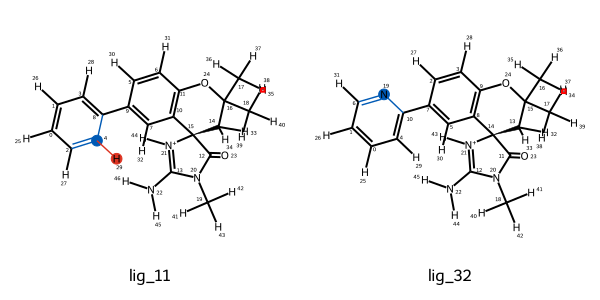

In [53]:
# Now find an edge within the spirocyclic series
edge = [edge for edge in network.edges if {edge.componentA.name, edge.componentB.name} == {"lig_11", "lig_32"}][0]
edge


In [54]:
# Higher score is better
edge.annotations

{'score': 0.951229424500714}

## Configure the `Protocols`

Before building the transformations for the network we need to configure the protocol settings for both the hybrid topology and separated topologies protocols. By default, the force fields used by these protocols match however changes to one protocol should be reflected in the other. We will also be using the `_adaptive_settings` method to automatically adjust the settings based on the systems involved in the transformation, this is particularly useful for the hybrid topology protocol which adjusts the solvent padding based on the presence of a receptor in the system.

In [65]:
from openfe.protocols.openmm_rfe import RelativeHybridTopologyProtocol
from openfe.protocols.openmm_septop import SepTopProtocol

# Configure the small molecule force field to be used by both protocols and the number of repeats per execution of the protocol
small_molecule_forcefield = "openff-2.3.0"
default_hybrid_settings = RelativeHybridTopologyProtocol.default_settings()
default_hybrid_settings.forcefield_settings.small_molecule_forcefield = small_molecule_forcefield
default_hybrid_settings.protocol_repeats = 1

default_septop_settings = SepTopProtocol.default_settings()
default_septop_settings.forcefield_settings.small_molecule_forcefield = small_molecule_forcefield
default_septop_settings.protocol_repeats = 1

## Building the `Transformations`

Now we can build the transformations for this network, assigning the appropriate protocol for each transformation. Here we will use the hybrid topology protocol for edges within each series and the separated topologies protocol for edges between the series.

Each protocol has different requirements for the `ChemicalSystem` compositions used to represent the end states of the transformation. This is due to the hybrid topology protocol requiring the `complex` and `solvent` legs be constructed manually as separate `Transformation` objects while the separated topologies protocol runs both the `complex` and `solvent` legs within a single `Transformation` object. The code below demonstrates how to build the transformations for both protocols while ensuring the correct `ChemicalSystem` objects are used for each protocol. For more information on the requirements for each protocol see the [examples documentation](https://docs.openfree.energy/en/stable/guide/setup/chemical_systems_and_thermodynamic_cycles.html#system-composition-examples).

In [67]:
from openfe.protocols.openmm_rfe import RelativeHybridTopologyProtocolSettings
from openfe.protocols.openmm_septop import SepTopSettings

# load the receptor from the provided PDB file and create the solvent component
protein = openfe.ProteinComponent.from_pdb_file("inputs/protein.pdb")
solvent = openfe.SolventComponent()


# define helper functions to build the transformations for each protocol
def build_hybrid_topology_transformation(edge: openfe.LigandAtomMapping, default_settings: RelativeHybridTopologyProtocolSettings, protein_comp: openfe.ProteinComponent, solvent_comp: openfe.SolventComponent) -> list[openfe.Transformation]:
    """Build the complex and solvent leg transformations for a given ligand atom mapping using the hybrid topology protocol."""
    transformations = []
    for leg in ["solvent", "complex"]:
        state_a_dict = {"ligand": edge.componentA, "solvent": solvent_comp}
        state_b_dict = {"ligand": edge.componentB, "solvent": solvent_comp}
        if leg == "complex":
            state_a_dict["protein"] = protein_comp
            state_b_dict["protein"] = protein_comp

        state_a = openfe.ChemicalSystem(state_a_dict, name=f"{edge.componentA.name}_{leg}")
        state_b = openfe.ChemicalSystem(state_b_dict, name=f"{edge.componentB.name}_{leg}")

        # adjust the settings based on the systems involved in the transformation
        ts_settings = RelativeHybridTopologyProtocol._adaptive_settings(
            stateA=state_a,
            stateB=state_b,
            mapping=edge,
            initial_settings=default_settings,
        )

        # create the transformation for this leg
        transformation = openfe.Transformation(
            stateA=state_a,
            stateB=state_b,
            mapping=edge,
            protocol=RelativeHybridTopologyProtocol(ts_settings),
            name=f"{leg}_{edge.componentA.name}_{edge.componentB.name}"
        )
        transformations.append(transformation)
    return transformations


def build_septop_transformation(edge: openfe.LigandAtomMapping, default_settings: SepTopSettings, protein_comp: openfe.ProteinComponent, solvent_comp: openfe.SolventComponent) -> list[openfe.Transformation]:
    """Build the transformation for a given ligand atom mapping using the separated topologies protocol."""
    state_a_dict = {"ligand": edge.componentA, "protein": protein_comp, "solvent": solvent_comp}
    state_b_dict = {"ligand": edge.componentB, "protein": protein_comp, "solvent": solvent_comp}

    state_a = openfe.ChemicalSystem(state_a_dict, name=f"{edge.componentA.name}_septop")
    state_b = openfe.ChemicalSystem(state_b_dict, name=f"{edge.componentB.name}_septop")

    # adjust the settings based on the systems involved in the transformation
    ts_settings = SepTopProtocol._adaptive_settings(
        stateA=state_a,
        stateB=state_b,
        initial_settings=default_settings,
    )

    # create the transformation for this edge
    transformation = openfe.Transformation(
        stateA=state_a,
        stateB=state_b,
        mapping=None,
        protocol=SepTopProtocol(ts_settings),
        name=f"{edge.componentA.name}_{edge.componentB.name}"
    )
    return [transformation, ]


We can now build the transformations required to execute the edges in the planned network. The code below iterates through the edges in the `LigandNetwork` and builds the appropriate transformations for each edge based on whether the edge is within a series or between series. The transformations can then be writen to disk which can be executed using the [openfe quickrun CLI](https://docs.openfree.energy/en/stable/guide/introduction.html#cli-workflow).

In [69]:
import pathlib

all_transformations = []
for edge in network.edges:
    if ligand_series_mapping[edge.componentA.name] == ligand_series_mapping[edge.componentB.name]:
        # build the hybrid topology transformations for edges within a series
        transformations = build_hybrid_topology_transformation(edge, default_hybrid_settings, protein, solvent)
    else:
        # build the separated topologies transformation for edges between series
        transformations = build_septop_transformation(edge, default_septop_settings, protein, solvent)

    # add the transformations to the network
    all_transformations.extend(transformations)

alchemical_network = openfe.AlchemicalNetwork(all_transformations)

# first we create the directory
transformation_dir = pathlib.Path("transformations")
transformation_dir.mkdir(exist_ok=True)

# then we write out each transformation
for transformation in alchemical_network.edges:
    transformation.to_json(transformation_dir / f"{transformation.name}.json")

We can also check how many transformations were created for each protocol. The hybrid topology protocol should have 44 transformations (22 edges * 2 legs) while the separated topologies protocol should have 6 transformations (6 connecting edges).

In [77]:
edges_per_protocol = {
    RelativeHybridTopologyProtocol: 0,
    SepTopProtocol: 0
}
for transformation in alchemical_network.edges:
    edges_per_protocol[transformation.protocol.__class__] += 1

edges_per_protocol

{openfe.protocols.openmm_rfe.hybridtop_protocols.RelativeHybridTopologyProtocol: 44,
 openfe.protocols.openmm_septop.equil_septop_method.SepTopProtocol: 6}